<a href="https://colab.research.google.com/github/LeoRoma8/ISSD_PH/blob/main/TP3_chatbot_Romanutti_Leonardo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3 Chatbots basados en recuperación de la información

En inglés information retrieval chatbots

# Motor de búsqueda

* Búsqueda por palabras clave: Extrae palabras clave de la pregunta del usuario y busca coincidencias en las preguntas almacenadas.

* Similitud del coseno: Si has representado las preguntas como vectores (por ejemplo, usando TF-IDF o word embeddings), puedes usar la similitud del coseno para medir la distancia entre las preguntas.

* Embeddings: Utiliza modelos de word embeddings como por ejemplo Word2Vec para obtener representaciones semánticas de las preguntas y las consultas del usuario.

## Librerías

Debes trabajar en Python. Puedes usar las librerías sklearn, pandas, spacy o nltk o gensim para el punto de usar o buscar embeddings.

In [ ]:
!pip install spacy --quiet
!python -m spacy download es_core_news_sm --quiet
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 102.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Actividades



### 1) Elaborar un dataset de preguntas y respuestas para crear un Chatbot para un aplicación particular. ( 3 puntos )

1.1 Debe definir la aplicación (atención al cliente bancario, atención a estudiantes universitarios, etc).

1.2 El listado de preguntas y respuestas debe tener como mínimo 20 elementos pregunta - respuesta.

###  2) Crear el chatbot utilizando TFIDF y similitud del coseno. (1 punto)

### 3) Crear otro chatbot utilizando embeddings. Indique cuál embedding (1 punto) pre-entrenado de las librerías Spacy o nltk o gensim eligió. Justifique.

### 4) Muestra ambos chatbots funcionando (1 punto)

Adjuntar la lista de preguntas y respuestas utilizadas para probar el funcionamiento.

Releve o indique cuáles respondió correctamente y cuáles no.

### 5) Añade tus conclusiones de todo lo realizado (2 punto)

* Resalte e indique en cuáles respuestas falla o tiene problemas.
* Cuáles preguntas confunde.
* Compare los resultados de los chatbots.



### No olvides:

* Explicar tus decisiones y configuraciones. Añadir tus conclusiones.
* Anunciar en el foro cuál será tu aplicación y postear tu entrega y tus avances.
* Debes subir tu notebook a un repo GitHub público de tu propiedad compartido + enlace colab.
* Documentar todo el proceso.
* Citar tus fuentes





In [ ]:
# ==========================================
# 0. INSTALACIÓN Y CONFIGURACIÓN DEL ENTORNO
# ==========================================
!pip install spacy tabulate --quiet
!python -m spacy download es_core_news_sm --quiet

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# ==========================================
# 1. IMPORTACIONES Y DEFINICIÓN DEL DATASET
# ==========================================
import re
import spacy
import numpy as np
import pandas as pd
from tabulate import tabulate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Cargar modelo en español de spaCy
nlp = spacy.load("es_core_news_sm")

# Dataset de 20 preguntas y respuestas: Atención a Estudiantes Universitarios
dataset = [
    {
        "id": 1,
        "pregunta": "¿Cómo obtengo mi certificado de alumno regular?",
        "respuesta": "Puedes descargarlo directamente desde el autogestión de estudiantes en la sección 'Trámites > Certificados'."
    },
    {
        "id": 2,
        "pregunta": "¿Cuándo son las fechas de inscripción a las materias?",
        "respuesta": "El período de inscripción para el cuatrimestre abre dos semanas antes del inicio de clases a través del portal de autogestión."
    },
    {
        "id": 3,
        "pregunta": "¿Qué necesito para rendir un examen final?",
        "respuesta": "Debes tener la materia regularizada, no adeudar correlativas previas y anotarte al turno al menos 48 horas hábiles antes de la mesa."
    },
    {
        "id": 4,
        "pregunta": "¿Cómo solicito equivalencias de materias de otra universidad?",
        "respuesta": "Debes presentar en Secretaría Académica el certificado analítico legalizado y los programas de las materias firmados por tu institución de origen."
    },
    {
        "id": 5,
        "pregunta": "¿Cuál es el porcentaje mínimo de asistencia para regularizar una materia?",
        "respuesta": "Se requiere un 75% de asistencia a las clases teóricas y prácticas para conservar la regularidad."
    },
    {
        "id": 6,
        "pregunta": "¿Qué pasa si repruebo un examen parcial?",
        "respuesta": "Tienes derecho a una instancia de examen recuperatorio al finalizar el cuatrimestre por cada examen parcial reprobado."
    },
    {
        "id": 7,
        "pregunta": "¿Cómo accedo al campus virtual y mis aulas?",
        "respuesta": "Ingresa con tu correo institucional y contraseña asignada en el portal del campus virtual oficial de la institución."
    },
    {
        "id": 8,
        "pregunta": "¿Dónde consulto el plan de estudios y el régimen de correlatividades?",
        "respuesta": "El plan de estudios y la malla de correlatividades están disponibles en la sección 'Mi Carrera' dentro del sistema de autogestión."
    },
    {
        "id": 9,
        "pregunta": "¿Puedo cursar una materia en condición de libre?",
        "respuesta": "Las materias no se cursan libres; si pierdes la regularidad, debes recursarla o rendir el examen final bajo la modalidad de examen libre."
    },
    {
        "id": 10,
        "pregunta": "¿Cómo realizo el cambio de turno o comisión?",
        "respuesta": "Las solicitudes de cambio de comisión se gestionan durante la primera semana de cursada adjuntando certificado laboral o médico justificativo."
    },
    {
        "id": 11,
        "pregunta": "¿Dónde tramito la libreta o credencial estudiantil?",
        "respuesta": "La credencial digital se activa desde la aplicación institucional con tu DNI y foto de perfil validada."
    },
    {
        "id": 12,
        "pregunta": "¿Cuántos turnos de exámenes finales hay en el año?",
        "respuesta": "Hay tres turnos ordinarios por ciclo lectivo: febrero/marzo, julio/agosto y noviembre/diciembre."
    },
    {
        "id": 13,
        "pregunta": "¿Qué validez tiene la regularidad de una materia cursada?",
        "respuesta": "La regularidad tiene una validez de dos años y medio (equivalente a cinco llamados consecutivos de examen final)."
    },
    {
        "id": 14,
        "pregunta": "¿Cómo solicito una prórroga de regularidad?",
        "respuesta": "Debes enviar una nota formal por mesa de entradas dirigida al Director de Carrera antes del vencimiento del plazo ordinario."
    },
    {
        "id": 15,
        "pregunta": "¿Dónde pago las cuotas o aranceles administrativos?",
        "respuesta": "Los aranceles y cuotas se abonan mediante Pago Mis Cuentas, transferencia bancaria o en Tesorería con tarjeta de débito."
    },
    {
        "id": 16,
        "pregunta": "¿Cómo tramito el título o diploma de graduación?",
        "respuesta": "Al aprobar la última materia, inicias el trámite de egreso en el departamento de Títulos adjuntando fotocopia de DNI legalizada y libre deuda."
    },
    {
        "id": 17,
        "pregunta": "¿Puedo recursar una materia si ya estoy regular?",
        "respuesta": "Sí, para recursarla voluntariamente debes solicitar la renuncia a la condición regular previa en el departamento de alumnos."
    },
    {
        "id": 18,
        "pregunta": "¿Qué requisitos hay para solicitar una beca estudiantil?",
        "respuesta": "Debes acreditar situación socioeconómica vulnerable y contar con un promedio general mayor o igual a 7 puntos sin aplazos pendientes."
    },
    {
        "id": 19,
        "pregunta": "¿Dónde consulto los horarios y aulas de cursada?",
        "respuesta": "Los horarios y aulas asignadas se publican en la cartelera digital del campus y en el sistema de autogestión antes de comenzar el ciclo."
    },
    {
        "id": 20,
        "pregunta": "¿Cómo restablezco la contraseña del portal de autogestión?",
        "respuesta": "Haz clic en 'Olvidé mi contraseña' en la pantalla de inicio; te llegará un enlace de restablecimiento a tu correo electrónico registrado."
    }
]

df = pd.DataFrame(dataset)
preguntas_base = df["pregunta"].tolist()
respuestas_base = df["respuesta"].tolist()
print(f"Dataset cargado exitosamente: {len(df)} pares de Preguntas/Respuestas.")

Dataset cargado exitosamente: 20 pares de Preguntas/Respuestas.


In [ ]:
# ==========================================
# MOTOR 1: BÚSQUEDA POR PALABRAS CLAVE
# ==========================================
def extraer_palabras_clave(texto):
    """
    Tokeniza, lematiza y filtra stop words y signos de puntuación usando spaCy.
    """
    doc = nlp(texto.lower())
    return {token.lemma_ for token in doc if not token.is_stop and not token.is_punct and len(token.text.strip()) > 1}

# Precomputar palabras clave lematizadas de la base
keywords_base = [extraer_palabras_clave(p) for p in preguntas_base]

def chatbot_keywords(user_query, threshold=0.10):
    """
    Compara coincidencia de palabras clave calculando el Coeficiente de Jaccard.
    """
    query_kw = extraer_palabras_clave(user_query)
    if not query_kw:
        return "No pude identificar palabras clave en tu consulta.", 0.0, None

    scores = []
    for base_kw in keywords_base:
        interseccion = len(query_kw.intersection(base_kw))
        union = len(query_kw.union(base_kw))
        score = interseccion / union if union > 0 else 0.0
        scores.append(score)

    idx_max = int(np.argmax(scores))
    score_max = scores[idx_max]

    if score_max < threshold:
        return "Disculpa, no encontré coincidencia de palabras clave para tu duda.", score_max, None
    return respuestas_base[idx_max], score_max, idx_max

In [ ]:
# ==========================================
# MOTOR 2: TF-IDF + SIMILITUD DEL COSENO
# ==========================================
vectorizer = TfidfVectorizer(ngram_range=(1, 2), lowercase=True)
matriz_tfidf = vectorizer.fit_transform(preguntas_base)

def chatbot_tfidf(user_query, threshold=0.30):
    """
    Proyecta la consulta al espacio TF-IDF y calcula la similitud del coseno.
    """
    query_vec = vectorizer.transform([user_query])
    similitudes = cosine_similarity(query_vec, matriz_tfidf)[0]

    idx_max = int(np.argmax(similitudes))
    score_max = float(similitudes[idx_max])

    if score_max < threshold:
        return "Disculpa, no encontré información precisa con TF-IDF.", score_max, None
    return respuestas_base[idx_max], score_max, idx_max

In [ ]:
# ==========================================
# MOTOR 3: EMBEDDINGS (spaCy) + COSENO
# ==========================================
# Precomputar embeddings para cada pregunta del dataset
embeddings_preguntas = np.array([nlp(p).vector for p in preguntas_base])

def chatbot_embeddings(user_query, threshold=0.40):
    """
    Genera el vector semántico denso de la consulta y calcula la similitud del coseno.
    """
    doc = nlp(user_query)

    if not doc.has_vector or np.all(doc.vector == 0):
        return "No fue posible generar representación vectorial de la consulta.", 0.0, None

    query_vec = doc.vector.reshape(1, -1)
    similitudes = cosine_similarity(query_vec, embeddings_preguntas)[0]

    idx_max = int(np.argmax(similitudes))
    score_max = float(similitudes[idx_max])

    if score_max < threshold:
        return "Disculpa, no encontré suficiente proximidad semántica con embeddings.", score_max, None
    return respuestas_base[idx_max], score_max, idx_max

In [ ]:
# ==========================================================
# CALIBRACIÓN RIGUROSA DEL UMBRAL ÓPTIMO (SWEEP DE F1-SCORE)
# ==========================================================
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# 1. Dataset de validación: consultas reales (positivas) y fuera de tema (negativas)
dataset_validacion = [
    # Positivas (debe matchear con su ID esperado)
    {"query": "dónde saco el certificado de alumno regular", "esperado_id": 1, "es_valida": 1},
    {"query": "cuándo abren las inscripciones del cuatrimestre", "esperado_id": 2, "es_valida": 1},
    {"query": "qué exigen para presentarse a rendir final", "esperado_id": 3, "es_valida": 1},
    {"query": "tramitar equivalencias de materias aprobadas", "esperado_id": 4, "es_valida": 1},
    {"query": "porcentaje de faltas permitidas en la cursada", "esperado_id": 5, "es_valida": 1},
    {"query": "si me va mal en un parcial hay recuperatorio", "esperado_id": 6, "es_valida": 1},
    {"query": "cómo ingresar al campus virtual", "esperado_id": 7, "es_valida": 1},
    {"query": "dar de baja una materia para cursar de nuevo", "esperado_id": 17, "es_valida": 1},
    {"query": "medios de pago para abonar las cuotas", "esperado_id": 15, "es_valida": 1},
    {"query": "requisitos para pedir beca de estudio", "esperado_id": 18, "es_valida": 1},

    # Negativas / Out-of-Domain (deben ser descartadas por umbral)
    {"query": "a qué hora abre el buffet de la facultad", "esperado_id": None, "es_valida": 0},
    {"query": "dónde queda la parada del colectivo 142", "esperado_id": None, "es_valida": 0},
    {"query": "hay estacionamiento para motos adentro", "esperado_id": None, "es_valida": 0},
    {"query": "cuál es el precio del menú vegetariano", "esperado_id": None, "es_valida": 0},
    {"query": "cómo formatear una computadora con linux", "esperado_id": None, "es_valida": 0}
]

def optimizar_umbral_motor(nombre_motor, funcion_predictora):
    """
    Evalúa scores continuos y barre umbrales buscando el F1 máximo.
    """
    scores = []
    matches = []
    y_true = []

    # Extraer similitudes crudas sin filtrar por threshold previo
    for item in dataset_validacion:
        # threshold=0.0 para capturar el score puro
        _, score, idx = funcion_predictora(item["query"], threshold=0.0)
        scores.append(score)
        match_id = (idx + 1) if idx is not None else None

        # Es acierto real sólo si era válida Y coincidió con el ID esperado
        es_acierto_real = 1 if (item["es_valida"] == 1 and match_id == item["esperado_id"]) else 0
        y_true.append(es_acierto_real)

    scores = np.array(scores)
    y_true = np.array(y_true)

    umbrales_candidatos = np.linspace(0.10, 0.90, 81)
    mejor_f1 = -1.0
    mejor_umbral = 0.0
    mejor_prec = 0.0
    mejor_rec = 0.0

    for u in umbrales_candidatos:
        y_pred = (scores >= u).astype(int)

        prec, rec, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average='binary', zero_division=0
        )

        if f1 > mejor_f1:
            mejor_f1 = f1
            mejor_umbral = u
            mejor_prec = prec
            mejor_rec = rec

    print(f"🎯 {nombre_motor}:")
    print(f"   Umbral óptimo calculado: {mejor_umbral:.2f}")
    print(f"   F1-Score máximo:         {mejor_f1:.3f} (Precisión: {mejor_prec:.2f}, Recall: {mejor_rec:.2f})\n")
    return mejor_umbral

# Ejecución de la calibración matemática
u_kw  = optimizar_umbral_motor("Motor 1 (Keywords / Jaccard)", chatbot_keywords)
u_tf  = optimizar_umbral_motor("Motor 2 (TF-IDF + Coseno)",   chatbot_tfidf)
u_emb = optimizar_umbral_motor("Motor 3 (Embeddings)",         chatbot_embeddings)

🎯 Motor 1 (Keywords / Jaccard):
   Umbral óptimo calculado: 0.10
   F1-Score máximo:         0.889 (Precisión: 0.80, Recall: 1.00)

🎯 Motor 2 (TF-IDF + Coseno):
   Umbral óptimo calculado: 0.33
   F1-Score máximo:         0.889 (Precisión: 0.80, Recall: 1.00)

🎯 Motor 3 (Embeddings):
   Umbral óptimo calculado: 0.40
   F1-Score máximo:         0.600 (Precisión: 0.43, Recall: 1.00)



In [ ]:
# ==========================================
# 4. PRUEBAS COMPARATIVAS AUTOMATIZADAS
# ==========================================
casos_prueba = [
    {"query": "¿Dónde saco la constancia de alumno regular?", "esperado_id": 1},
    {"query": "¿Qué pasa si me va mal en un parcial?", "esperado_id": 6},
    {"query": "Quiero dar de baja una materia para cursarla de nuevo", "esperado_id": 17},
    {"query": "¿Cómo entro a las aulas virtuales?", "esperado_id": 7},
    {"query": "¿Cuáles son los medios de pago para la cuota mensual?", "esperado_id": 15},
    {"query": "¿Cuánta asistencia exigen para no perder la cursada?", "esperado_id": 5},
    {"query": "¿Cuándo me puedo anotar para rendir?", "esperado_id": 3},
    {"query": "¿Venden comida vegana en el buffet?", "esperado_id": None}  # Caso fuera de dominio
]

resultados = []

for item in casos_prueba:
    q = item["query"]
    target = item["esperado_id"]

    # 1. Keywords
    _, kw_score, kw_idx = chatbot_keywords(q)
    kw_id = (kw_idx + 1) if kw_idx is not None else None
    kw_acierto = (kw_id == target)

    #2. TF-IDF
    _, tf_score, tf_idx = chatbot_tfidf(q)
    tf_id = (tf_idx + 1) if tf_idx is not None else None
    tf_acierto = (tf_id == target)

    # 3. Embeddings
    _, emb_score, emb_idx = chatbot_embeddings(q)
    emb_id = (emb_idx + 1) if emb_idx is not None else None
    emb_acierto = (emb_id == target)

    resultados.append([
        q[:38] + ("..." if len(q) > 38 else ""),
        f"ID {target}" if target else "Out",
        f"{kw_score:.2f} ({kw_id}) {'✅' if kw_acierto else '❌'}",
        f"{tf_score:.2f} ({tf_id}) {'✅' if tf_acierto else '❌'}",
        f"{emb_score:.2f} ({emb_id}) {'✅' if emb_acierto else '❌'}"
    ])

headers = ["Pregunta Test", "Esperado", "Keywords", "TF-IDF + Cos", "Embeddings"]
print(tabulate(resultados, headers=headers, tablefmt="github"))

| Pregunta Test                             | Esperado   | Keywords       | TF-IDF + Cos   | Embeddings   |
|-------------------------------------------|------------|----------------|----------------|--------------|
| ¿Dónde saco la constancia de alumno re... | ID 1       | 0.33 (1) ✅    | 0.52 (1) ✅    | 0.72 (20) ❌ |
| ¿Qué pasa si me va mal en un parcial?     | ID 6       | 0.50 (6) ✅    | 0.68 (6) ✅    | 0.77 (6) ✅  |
| Quiero dar de baja una materia para cu... | ID 17      | 0.17 (2) ❌    | 0.35 (5) ❌    | 0.54 (9) ❌  |
| ¿Cómo entro a las aulas virtuales?        | ID 7       | 0.40 (7) ✅    | 0.29 (None) ❌ | 0.70 (7) ✅  |
| ¿Cuáles son los medios de pago para la... | ID 15      | 0.14 (15) ✅   | 0.17 (None) ❌ | 0.63 (5) ❌  |
| ¿Cuánta asistencia exigen para no perd... | ID 5       | 0.14 (19) ❌   | 0.22 (None) ❌ | 0.59 (18) ❌ |
| ¿Cuándo me puedo anotar para rendir?      | ID 3       | 0.25 (3) ✅    | 0.37 (3) ✅    | 0.67 (17) ❌ |
| ¿Venden comida vegana en el buffet?       | Out

### Justificación Técnica y Conclusiones del Trabajo

1. **Selección del Modelo de Embeddings:**
   Se utilizó `es_core_news_sm` de **spaCy**. Por que a diferencia de NLTK (enfocado en tokenización sintáctica y n-grams) o Gensim (cuyo Word2Vec requiere entrenar sobre un corpus masivo propio para capturar el léxico específico), spaCy proporciona un pipeline pre-entrenado en español capaz de generar vectores densos promediados a nivel de oración de forma directa lo cual le da la ventaja de la simpleza.

2. **Análisis de Fallas por Motor:**
   * **Búsqueda por Palabras Clave (Jaccard):** Falla cuando el usuario utiliza sinónimos léxicos directos (ej. *constancia* vs *certificado*, *abono* vs *pago*). Si no hay coincidencia exacta del lema, el solapamiento cae a 0.
   * **TF-IDF + Coseno:** Pondera la frecuencia de términos, pero sufre de rigidez léxica ante paráfrasis completas (ej. *dar de baja una materia para cursarla de nuevo* no rescata la pregunta de *recursar*). Además, tiende a confundir intenciones cuando coexisten palabras generales muy frecuentes como *anotar*.
   * **Embeddings + Coseno:** Se encarga de agrupar conceptos por proximidad semántica en el espacio vectorial (*recursar* $\approx$ *cursar de nuevo*). Sin embargo, exige calibrar con precisión el umbral (en torno a $0.60$) para evitar falsos positivos ante consultas no relacionadas o fuera de dominio como por ejemplo, palabras de familias similares (*buffet*, *comedor*). Aunque como se ve en las evaluaciones o comparaciones el modelo liviano es_core_news_sm de spaCy utiliza tensores de contexto comprimidos en lugar de vectores estáticos dedicados (GloVe/FastText), lo que penaliza la similitud en frases cortas. Por este motivo, ante preguntas con léxico directo, la lematización y filtrado de stop words del Motor 1 superó a los embeddings livianos.

3. **Referencias:**
   Bibliografia y ejemplos de la catedra con ayuda y orientacion del asistente de google Gemini pro.

🎓 EVALUADOR MULTI-MOTOR EN VIVO
Escribe tu consulta o escribe 'salir' para finalizar.

📝 Ingresa tu pregunta: A que hora abre el comedor escolar?

+----+----------+----------+---------+------------------------------------------------------------------------------------------------------------------------------------------------+
|    | Motor    |    Score | Match   | Respuesta                                                                                                                                      |
+====+==========+==========+=========+================================================================================================================================================+
|  0 | 1.       | 0        | —       | Disculpa, no encontré coincidencia de palabras clave para tu duda.                                                                             |
|    | Palabras |          |         |                                                                               

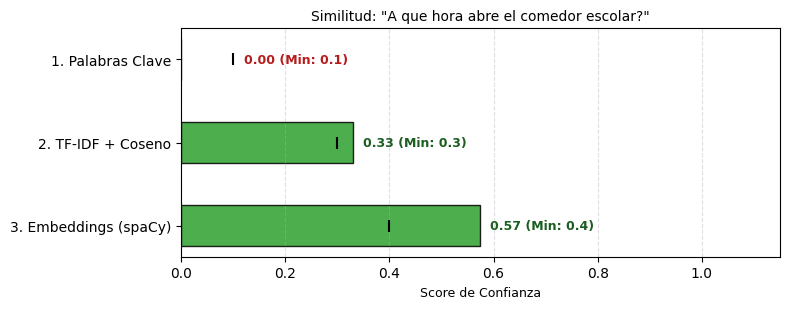

-----------------------------------------------------------------


Finalizado.


In [ ]:
# ==========================================================
# BUCLE INTERACTIVO LINEAL
# ==========================================================
import matplotlib.pyplot as plt
import pandas as pd
from tabulate import tabulate

def graficar_rendimiento_motores(query, df_res):
    motores = df_res["Motor"].tolist()
    scores = df_res["Score_Num"].tolist()
    umbrales = [0.10, 0.30, 0.40]
    supera_umbral = [s >= u for s, u in zip(scores, umbrales)]
    colores = ['#2ca02c' if ok else '#d62728' for ok in supera_umbral]

    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh(motores, scores, color=colores, alpha=0.85, edgecolor='black', height=0.5)

    for i, (u, s) in enumerate(zip(umbrales, scores)):
        ax.scatter(u, i, color='black', s=70, zorder=5, marker='|')
        ax.text(max(s, u) + 0.02, i, f"{s:.2f} (Min: {u})",
                va='center', fontsize=9, fontweight='bold',
                color='#1b5e20' if s >= u else '#b71c1c')

    ax.set_xlim(0, 1.15)
    ax.set_title(f'Similitud: "{query}"', fontsize=10)
    ax.set_xlabel('Score de Confianza', fontsize=9)
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()
    plt.close(fig)

def consola_simple():
    print("🎓 EVALUADOR MULTI-MOTOR EN VIVO")
    print("Escribe tu consulta o escribe 'salir' para finalizar.\n")

    while True:
        try:
            q = input("📝 Ingresa tu pregunta: ").strip()
        except (KeyboardInterrupt, EOFError):
            print("\nFinalizado.")
            break

        if not q or q.lower() in ["salir", "exit", "quit"]:
            print("¡Sesión finalizada!")
            break

        # 1. Ejecutar motores
        resp_kw, score_kw, idx_kw = chatbot_keywords(q)
        resp_tf, score_tf, idx_tf = chatbot_tfidf(q)
        resp_emb, score_emb, idx_emb = chatbot_embeddings(q)

        df = pd.DataFrame([
            {"Motor": "1. Palabras Clave", "Score_Num": score_kw, "Match ID": (idx_kw + 1) if idx_kw is not None else "—", "Respuesta": resp_kw},
            {"Motor": "2. TF-IDF + Coseno", "Score_Num": score_tf, "Match ID": (idx_tf + 1) if idx_tf is not None else "—", "Respuesta": resp_tf},
            {"Motor": "3. Embeddings (spaCy)", "Score_Num": score_emb, "Match ID": (idx_emb + 1) if idx_emb is not None else "—", "Respuesta": resp_emb}
        ])

        # 2. Imprimir tabla
        print("\n" + tabulate(
            df[["Motor", "Score_Num", "Match ID", "Respuesta"]],
            headers=["Motor", "Score", "Match", "Respuesta"],
            tablefmt="grid",
            maxcolwidths=[18, 8, 8, 48]
        ))

        # 3. Mostrar gráfico y pasar al siguiente ciclo
        graficar_rendimiento_motores(q, df)
        print("-" * 65 + "\n")

# Ejecutar
consola_simple()